# Obligatorio de Machine Learning: cancelación de reservas

**Objetivo:** preparar y auditar el dataset para predecir `is_canceled`.

Esta primera etapa presenta resultados reales del archivo recibido. No elimina columnas o filas, no imputa valores y no entrena modelos.

## 1. Requisitos y alcance identificado

### Requisitos obligatorios de esta etapa

1. Mantener una estructura de proyecto reproducible.
2. Preparar un notebook ejecutable desde cero en Google Colab.
3. Cargar el CSV y verificar dimensiones, tipos, nulos, duplicados y distribución de `is_canceled`.
4. Auditar posibles fugas de información, especialmente `reservation_status` y `reservation_status_date`.
5. Proponer partición y validación sin entrenar modelos.
6. Mostrar resultados reales y justificar las decisiones.

### Qué aporta el PDF adjunto

El PDF es el artículo técnico *Hotel booking demand datasets* (Antonio, Almeida y Nunes, 2019), no una rúbrica universitaria. Documenta dos hoteles de Portugal, reservas con llegada entre julio de 2015 y agosto de 2017 y el objetivo de cancelación. También advierte que la fecha del objetivo debe ser posterior a las variables de entrada para evitar fuga de información.

La fuente indica que valores `NULL` en variables categóricas como `agent` y `company` pueden significar *no aplica*. Por eso se reportan tal como los interpreta `pandas`, pero no se imputan ni se decide todavía su tratamiento semántico.

## 2. Entorno y carga reproducible

In [1]:
from pathlib import Path
from io import StringIO
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")

Python: 3.13.5
pandas: 2.2.3
numpy: 2.1.3


In [2]:
candidates = [
    Path("data/hotel_bookings.csv"),
    Path("../data/hotel_bookings.csv"),
    Path("/content/hotel_bookings.csv"),
]
data_path = next((path for path in candidates if path.exists()), None)

if data_path is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "No se encontró data/hotel_bookings.csv. "
            "Ejecutá el notebook desde la raíz del proyecto o copiá el archivo."
        ) from exc
    print("Seleccioná hotel_bookings.csv en el diálogo de Colab.")
    uploaded = files.upload()
    if "hotel_bookings.csv" not in uploaded:
        raise FileNotFoundError("Se debe subir un archivo llamado hotel_bookings.csv")
    data_path = Path("hotel_bookings.csv")

df = pd.read_csv(data_path)
print(f"Archivo cargado: {data_path}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Archivo cargado: ..\data\hotel_bookings.csv


Dimensiones: 119,390 filas x 32 columnas


In [3]:
display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3. Auditoría inicial de calidad

In [4]:
buffer = StringIO()
df.info(buf=buffer)
print(buffer.getvalue())

type_summary = (
    df.dtypes.astype(str)
    .rename("dtype")
    .to_frame()
    .assign(unique_values=df.nunique(dropna=True))
)
display(type_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

,dtype,unique_values
hotel,object,2
is_canceled,int64,2
lead_time,int64,479
arrival_date_year,int64,3
arrival_date_month,object,12
arrival_date_week_number,int64,53
arrival_date_day_of_month,int64,31
stays_in_weekend_nights,int64,17
stays_in_week_nights,int64,35
adults,int64,14


In [5]:
missing = (
    df.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
display(missing)

raw_nullable = pd.read_csv(
    data_path,
    usecols=["children", "country", "agent", "company"],
    keep_default_na=False,
    dtype=str,
)
sentinels = []
for column in raw_nullable.columns:
    for token in ["", "NA", "NULL"]:
        count = int((raw_nullable[column].astype(str) == token).sum())
        if count:
            sentinels.append({"column": column, "raw_token": token or "<empty>", "count": count})
display(pd.DataFrame(sentinels))
print("No se imputó ningún valor. La tabla distingue el resultado de pandas del token crudo del CSV.")

,missing_count,missing_pct
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


,column,raw_token,count
0,children,NA,4
1,country,NULL,488
2,agent,NULL,16340
3,company,NULL,112593


No se imputó ningún valor. La tabla distingue el resultado de pandas del token crudo del CSV.


In [6]:
duplicate_count = int(df.duplicated().sum())
print(f"Filas duplicadas exactas, contando desde la segunda aparición: {duplicate_count:,}")
print(f"Filas únicas exactas: {len(df.drop_duplicates()):,}")
print("No se eliminaron duplicados: su definición y tratamiento requieren una decisión metodológica posterior.")

Filas duplicadas exactas, contando desde la segunda aparición: 31,994
Filas únicas exactas: 87,396
No se eliminaron duplicados: su definición y tratamiento requieren una decisión metodológica posterior.


## 4. Distribución del objetivo

,count,percentage
is_canceled,,
0,75166,62.958372
1,44224,37.041628


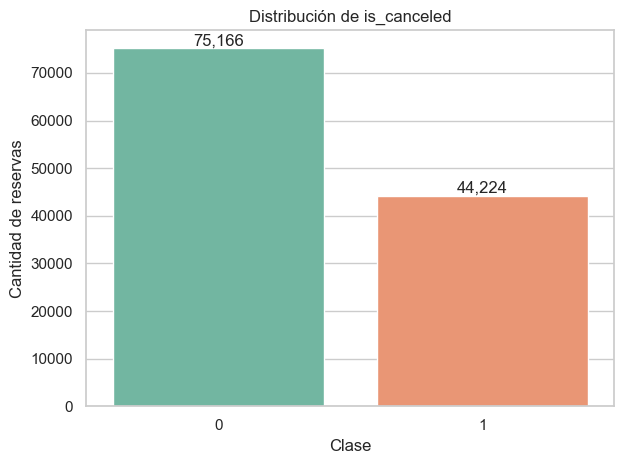

In [7]:
target_distribution = pd.DataFrame({
    "count": df["is_canceled"].value_counts().sort_index(),
    "percentage": 100 * df["is_canceled"].value_counts(normalize=True).sort_index(),
})
display(target_distribution)

ax = sns.countplot(data=df, x="is_canceled", hue="is_canceled", legend=False, palette="Set2")
ax.set(title="Distribución de is_canceled", xlabel="Clase", ylabel="Cantidad de reservas")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
plt.tight_layout()
plt.show()

## 5. Auditoría de fuga de información

In [8]:
status_vs_target = pd.crosstab(
    df["reservation_status"],
    df["is_canceled"],
    margins=True,
)
display(status_vs_target)

status_date = pd.to_datetime(df["reservation_status_date"], errors="raise")
print("Rango de reservation_status_date:", status_date.min().date(), "a", status_date.max().date())

is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


Rango de reservation_status_date: 2014-10-17 a 2017-09-14


### Decisión sobre fuga

- **`reservation_status`: fuga directa.** `Check-Out` coincide sólo con `is_canceled=0`; `Canceled` y `No-Show` coinciden sólo con `is_canceled=1`. La variable revela el resultado.
- **`reservation_status_date`: fuga temporal.** Es la fecha en la que se fijó el último estado. Puede conocerse después de la cancelación, el no-show o el check-out. No representa información disponible al emitir una predicción previa al resultado.
- **Variables que requieren confirmar el instante de predicción:** `assigned_room_type`, `booking_changes`, `country`, `deposit_type` y `days_in_waiting_list`. El artículo indica que algunos valores pueden cambiar hasta el check-in/cancelación o conocerse durante la operación. No se declaran automáticamente como fuga, pero deberán incluirse sólo si estaban disponibles en el momento exacto definido para predecir.

Las columnas permanecen en `df` para conservar el dataset original. En una etapa de modelado se construiría una lista explícita de predictores excluyendo las variables no disponibles, con la justificación documentada.

## 6. Estrategia de partición y validación propuesta

In [9]:
month_number = {
    month: number
    for number, month in enumerate(
        ["January", "February", "March", "April", "May", "June",
         "July", "August", "September", "October", "November", "December"],
        start=1,
    )
}
arrival_date = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": df["arrival_date_month"].map(month_number),
    "day": df["arrival_date_day_of_month"],
})
print("Rango de llegadas:", arrival_date.min().date(), "a", arrival_date.max().date())

split = pd.Series(index=df.index, dtype="object")
split.loc[arrival_date <= "2016-12-31"] = "Entrenamiento: 2015-07 a 2016-12"
split.loc[arrival_date.between("2017-01-01", "2017-04-30")] = "Validación: 2017-01 a 2017-04"
split.loc[arrival_date >= "2017-05-01"] = "Test: 2017-05 a 2017-08"

split_summary = (
    pd.DataFrame({"split": split, "is_canceled": df["is_canceled"]})
    .groupby("split", sort=False)["is_canceled"]
    .agg(rows="size", canceled="sum", cancellation_rate="mean")
)
split_summary["not_canceled"] = split_summary["rows"] - split_summary["canceled"]
split_summary["cancellation_rate_pct"] = 100 * split_summary.pop("cancellation_rate")
display(split_summary[["rows", "not_canceled", "canceled", "cancellation_rate_pct"]])

Rango de llegadas: 2015-07-01 a 2017-08-31


,rows,not_canceled,canceled,cancellation_rate_pct
split,,,,
Entrenamiento: 2015-07 a 2016-12,78703,50224,28479,36.185406
Validación: 2017-01 a 2017-04,18489,11745,6744,36.475742
Test: 2017-05 a 2017-08,22198,13197,9001,40.548698


In [10]:
folds = [
    ("2015-12-31", "2016-01-01", "2016-04-30"),
    ("2016-04-30", "2016-05-01", "2016-08-31"),
    ("2016-08-31", "2016-09-01", "2016-12-31"),
]
fold_rows = []
for fold_number, (train_end, val_start, val_end) in enumerate(folds, start=1):
    train_mask = arrival_date <= train_end
    val_mask = arrival_date.between(val_start, val_end)
    fold_rows.append({
        "fold": fold_number,
        "train_end": train_end,
        "train_rows": int(train_mask.sum()),
        "train_cancellation_pct": 100 * df.loc[train_mask, "is_canceled"].mean(),
        "validation_period": f"{val_start} a {val_end}",
        "validation_rows": int(val_mask.sum()),
        "validation_cancellation_pct": 100 * df.loc[val_mask, "is_canceled"].mean(),
    })
display(pd.DataFrame(fold_rows))

,fold,train_end,train_rows,train_cancellation_pct,validation_period,validation_rows,validation_cancellation_pct
0,1,2015-12-31,21996,37.015821,2016-01-01 a 2016-04-30,16391,33.140138
1,2,2016-04-30,38387,35.360929,2016-05-01 a 2016-08-31,20405,35.947072
2,3,2016-08-31,58792,35.564362,2016-09-01 a 2016-12-31,19911,38.019185


### Justificación

Se propone una partición **temporal** porque el uso real consiste en predecir reservas futuras con información histórica. Un reparto aleatorio mezclaría períodos y podría producir una estimación optimista ante cambios estacionales u operativos.

- **Entrenamiento:** julio de 2015 a diciembre de 2016.
- **Validación:** enero a abril de 2017, para decisiones de selección y ajuste.
- **Test final:** mayo a agosto de 2017, reservado y sin usar hasta la evaluación final.
- **Comparación futura de modelos:** validación de ventana expansiva dentro del bloque de entrenamiento, respetando el orden temporal.
- **Sin entrenamiento en esta etapa:** las máscaras y los resúmenes sólo verifican que la estrategia sea viable y que ambas clases estén representadas.

Antes de entrenar habrá que fijar el instante exacto de predicción (por ejemplo, al crear la reserva o siete días antes de la llegada). Esa definición determina qué variables estaban realmente disponibles y, por tanto, cuáles son predictores válidos.

## 7. Conclusiones de la etapa

- El archivo contiene 119.390 reservas y 32 columnas.
- `is_canceled=1` representa 44.224 reservas (37,04%).
- `pandas` identifica ausencias en `company`, `agent`, `country` y `children`; los tokens crudos se muestran para no confundir ausencia técnica con *no aplica*.
- Hay 31.994 filas duplicadas exactas contando desde la segunda aparición. Se conservan hasta definir si representan errores o reservas legítimamente idénticas sin identificador.
- `reservation_status` y `reservation_status_date` no deben entrar como predictores.
- La partición temporal propuesta deja un test reciente y revela un aumento de la tasa de cancelación en el último bloque, lo que refuerza la necesidad de evaluar deriva temporal.
- No se entrenó ningún modelo y el dataframe original permanece sin imputaciones ni eliminaciones.